In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


In [2]:
csv_path = "ETH-USD.csv"
df = pd.read_csv(csv_path)
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2017-11-09,308.644989,329.451996,307.056000,320.884003,320.884003,893249984
1,2017-11-10,320.670990,324.717987,294.541992,299.252991,299.252991,885985984
2,2017-11-11,298.585999,319.453003,298.191986,314.681000,314.681000,842300992
3,2017-11-12,314.690002,319.153015,298.513000,307.907990,307.907990,1613479936
4,2017-11-13,307.024994,328.415009,307.024994,316.716003,316.716003,1041889984


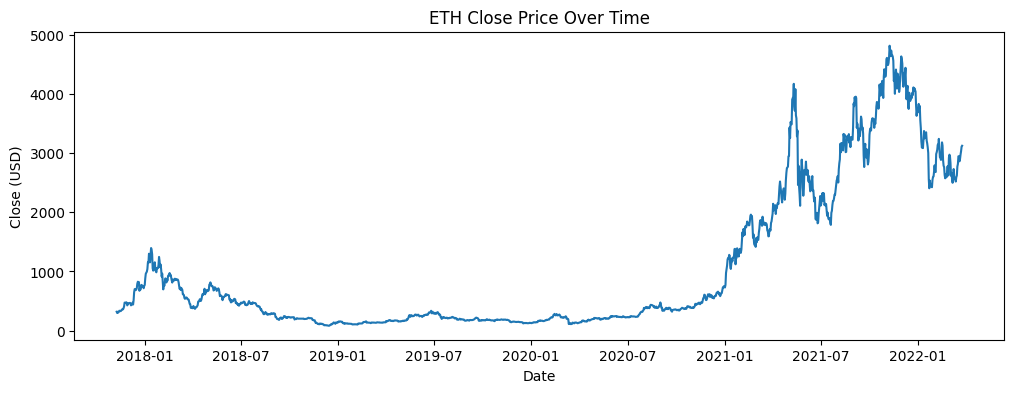

In [4]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

# Keep the target series (Close)
series = df[["Date", "Close"]].dropna()

plt.figure(figsize=(12,4))
plt.plot(series["Date"], series["Close"])
plt.title("ETH Close Price Over Time")
plt.xlabel("Date")
plt.ylabel("Close (USD)")
plt.show()

In [5]:
close_values = series["Close"].values.reshape(-1, 1)

n = len(close_values)
train_end = int(n * 0.80)
val_end   = int(n * 0.85)

train_raw = close_values[:train_end]
val_raw   = close_values[train_end:val_end]
test_raw  = close_values[val_end:]

scaler = MinMaxScaler()
train = scaler.fit_transform(train_raw)
val   = scaler.transform(val_raw)
test  = scaler.transform(test_raw)

train.shape, val.shape, test.shape


((1278, 1), (80, 1), (240, 1))

In [6]:
WINDOW = 30

def make_windows(data, window=30):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i-window:i])   # previous window days
        y.append(data[i])            # next day
    return np.array(X), np.array(y)

X_train, y_train = make_windows(train, WINDOW)
X_val,   y_val   = make_windows(val, WINDOW)
X_test,  y_test  = make_windows(test, WINDOW)

X_train.shape, y_train.shape


((1248, 30, 1), (1248, 1))

In [59]:
tf.random.set_seed(42)

model = keras.Sequential([
    layers.Input(shape=(WINDOW, 1)),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(16,),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-2),
    loss="mse",
    metrics=["mae"]
)

model.summary()


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_13 (LSTM)                  │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_14 (LSTM)                  │ (None, 16)             │         5,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,657 (88.50 KB)

 Trainable params: 22,657 (88.50 KB)

 Non-trainable params: 0 (0.00 B)

In [61]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 6.7879e-04 - mae: 0.0160 - val_loss: 0.0060 - val_mae: 0.0718
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0013 - mae: 0.0233 - val_loss: 0.0016 - val_mae: 0.0314
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 8.3104e-04 - mae: 0.0181 - val_loss: 0.0016 - val_mae: 0.0326
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 7.9667e-04 - mae: 0.0184 - val_loss: 0.0019 - val_mae: 0.0359
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 7.8934e-04 - mae: 0.0176 - val_loss: 0.0050 - val_mae: 0.0648
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 9.8195e-04 - mae: 0.0201 - val_loss: 9.2644e-04 - val_mae: 0.0255
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 9.9490e-04 - mae: 0.0198 - val_loss: 0.0015 - val_mae: 0.0308
Epoch 8/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0010 - mae: 0.0197 - val_loss: 0.0015 - val_mae: 0.0324
Epoch 9/100
39/39 ━━━━━━━━━━

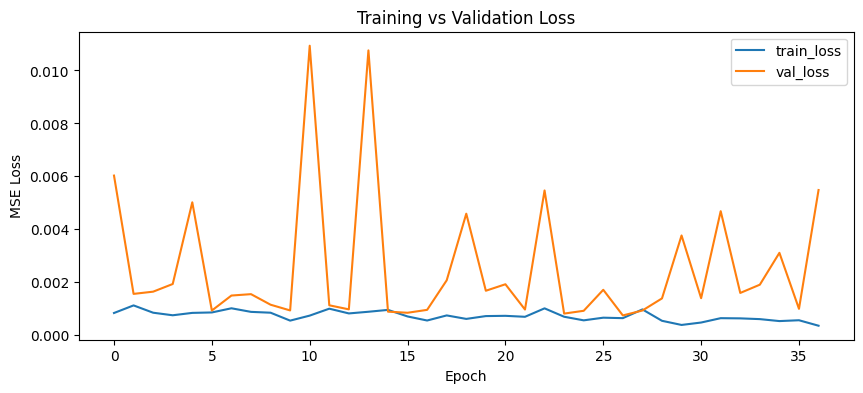

In [62]:
plt.figure(figsize=(10,4))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

In [63]:
pred_test = model.predict(X_test)

# Metrics on SCALED data (0-1 range)
mae  = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))
print(f"Test MAE:  {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")

# Still inverse transform for plotting
y_test_usd = scaler.inverse_transform(y_test)
pred_usd   = scaler.inverse_transform(pred_test)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Test MAE:  0.0369
Test RMSE: 0.0456


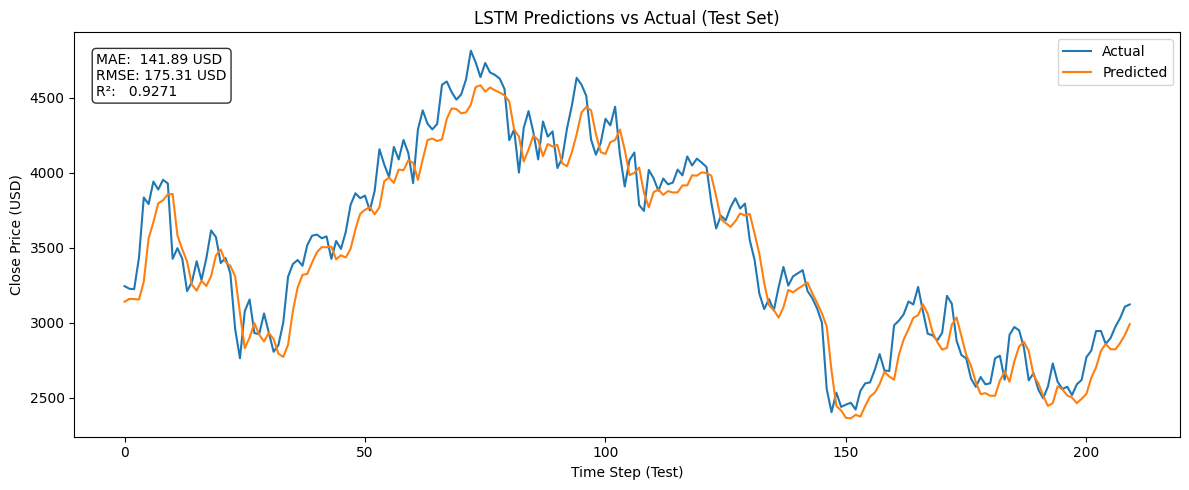

In [64]:

mae = mean_absolute_error(y_test_usd, pred_usd)
rmse = np.sqrt(mean_squared_error(y_test_usd, pred_usd))
r2 = r2_score(y_test_usd, pred_usd)

plt.figure(figsize=(12, 5))
plt.plot(y_test_usd, label="Actual")
plt.plot(pred_usd, label="Predicted")
plt.title("LSTM Predictions vs Actual (Test Set)")
plt.xlabel("Time Step (Test)")
plt.ylabel("Close Price (USD)")

# metrics as text box inside the plot
metrics_text = f"MAE:  {mae:.2f} USD\nRMSE: {rmse:.2f} USD\nR²:   {r2:.4f}"
plt.gca().text(
    0.02, 0.95, metrics_text,
    transform=plt.gca().transAxes,
    fontsize=10, verticalalignment='top',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)

plt.legend()
plt.tight_layout()
plt.show()